# Augmentation

RT has neither bird identity nor syllable labels, and BWPS has no syllable labels. We therefore predict both from the duration sequences alone.

**Bird identification.** Birds correspond to blocks of consecutive chunks, so it suffices to find the boundaries between birds. We compute the dynamic time warping (DTW) dissimilarity between chunks in a sliding window, which should peak at the boundaries between individuals, and detect changepoints at those peaks. We evaluate this on the datasets with known bird identity.

**Label prediction.** We fit a hidden Markov model (HMM) to the chunks of each bird and use its states as syllable labels. This works when the units of a bird have distinct, compact durations. Spectrally distinct units with a similar duration may be merged into one label, so we likely underestimate the number of labels.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

import sys
sys.path.append('../')

from src.data import load_units
from src.hmm.utils import  evaluate
from src.pipeline.predict_bird_ids import predict_bird_ids
from src.viz.changepoints import plot_changepoints
from src.viz.heatmap import per_column_heatmap, cmap_slice
from src.viz.utils import savefig, set_mpl_style, ylabel_annot
set_mpl_style()

from src.constants import DATASETS, RHYTHM_TYPES
UNIT_TYPE_LABELS = dict(ioi='IOIs', dur='durations', bound='boundaries')
rhythm_types = pd.DataFrame.from_dict(RHYTHM_TYPES, orient='index').rename_axis('rhythm_type')
rhythm_types['unit_type_label'] = rhythm_types['unit_type'].map(UNIT_TYPE_LABELS)
dataset_rhythm_types = [(d, r) for d, spec in DATASETS.items() for r in spec['rhythm_types']]

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



## Bird identity

### Example

Text(0, 0.5, 'changepoint score \n(based on dtw distance)')

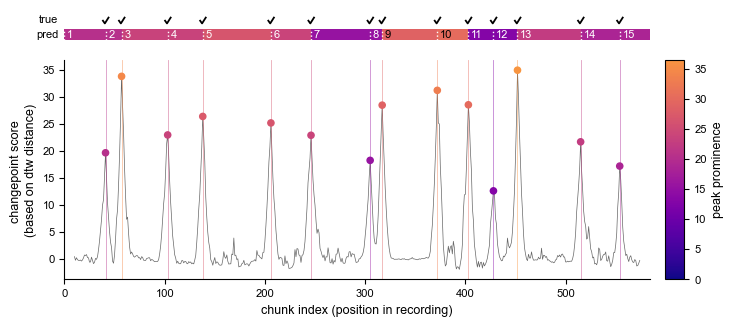

In [2]:
# Illustration
units = load_units('ns', 'syll_ioi', use_milliseconds=True)
result = predict_bird_ids(units, half_window=10, min_gap=5, id_prefix='ns-pred-')
fig, ax_tl, ax = plot_changepoints(
    result,
    result['n_chunks'],
    true_breakpoints=result['true_breakpoints'],
    tolerance=5,
)
ax.set_xlabel('chunk index (position in recording)');
ax.set_ylabel('changepoint score \n(based on dtw distance)')

### Main statistics

In [3]:
# Collect all statistics
bird_scores = []
for dataset_id, rhythm_type in dataset_rhythm_types:
    if dataset_id == 'rt':
        continue
    units = load_units(dataset_id, rhythm_type)
    units = units[~units['bird_id'].str.endswith('-tutee')]

    # Create chunk ids
    units['chunk_id'] = units['bird_id'] + '-' + units['chunk_idx'].astype(str).str.zfill(3)

    # Df with actual bird ids and bird_id_pred, one line per chunk.
    comparison = units.groupby('chunk_id')[['bird_id', 'bird_id_pred']].first()

    # Evaluation stats
    scores = evaluate(comparison['bird_id'], comparison['bird_id_pred'])
    subset = {k: scores[k] for k in [
        'accuracy', 'precision', 'recall', 'f1-score', 'support', 'homogeneity',
        'completeness', 'v_measure', 'adjusted_rand_score']
        }
    
    bird_scores.append(dict(
        dataset_id=dataset_id,
        rhythm_type=rhythm_type,
        label=RHYTHM_TYPES[rhythm_type]['label'],
        order=list(RHYTHM_TYPES).index(rhythm_type),
        **subset,
    ))

bird_scores = pd.DataFrame(bird_scores).set_index(['dataset_id', 'rhythm_type'])

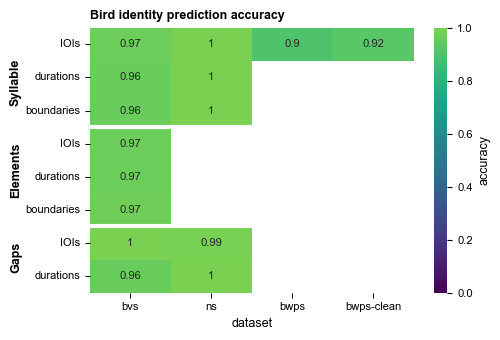

In [4]:
# Plot
bird_accuracies = pd.concat([
    (bird_scores['accuracy']
        .unstack('dataset_id')
        .reindex(
            columns=['bvs', 'ns', 'bwps', 'bwps-clean'],
            index=DATASETS['bvs']['rhythm_types']
        )
    ),
    rhythm_types['unit_type_label']
], axis=1).set_index('unit_type_label')

plt.figure(figsize=(5, 3.5))
sns.heatmap(
    bird_accuracies, 
    annot=True, 
    cmap=cmap_slice('viridis', 0, 0.8), 
    vmin=0, 
    vmax=1,
    annot_kws=dict(fontsize=8),
    cbar_kws=dict(label='accuracy')
)

ylabel_annot('Syllable', y=.75)
ylabel_annot('Elements', y=.5)
ylabel_annot('Gaps', y=.25)
plt.axhline(6, c='w', lw=3)
plt.axhline(3, c='w', lw=3)

plt.title('Bird identity prediction accuracy', x=0, ha='left', fontweight='bold')
plt.xlabel('dataset')
plt.ylabel(None)
plt.tight_layout()


### Additional metrics

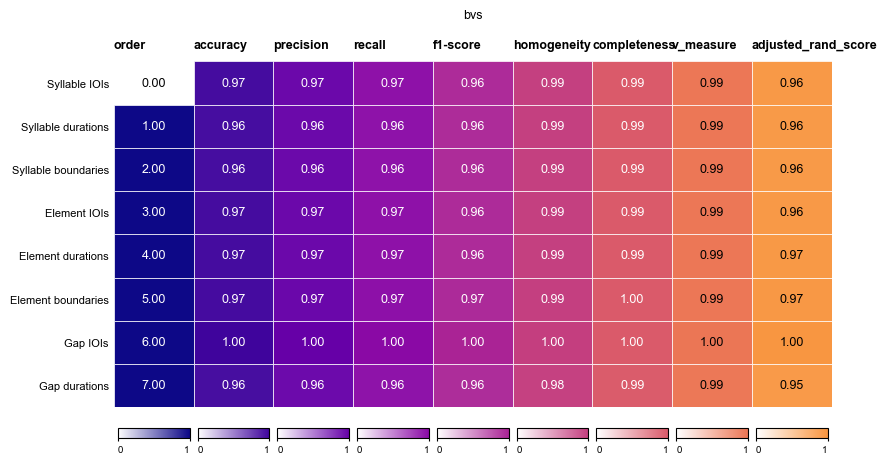

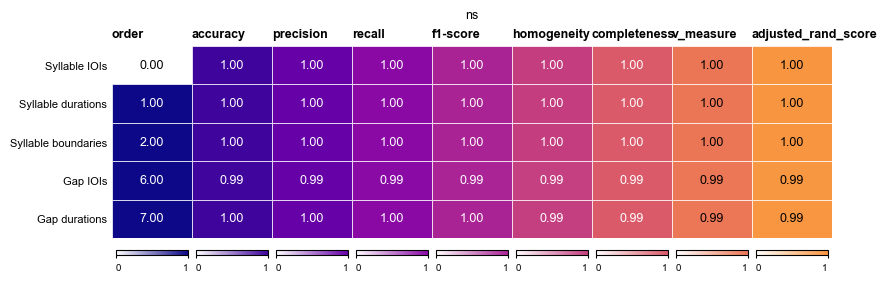

/var/folders/nf/0r2pjy2n46z5hrfxh12jx_p00000gn/T/ipykernel_87012/3728636997.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


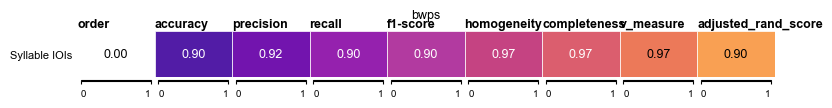

/var/folders/nf/0r2pjy2n46z5hrfxh12jx_p00000gn/T/ipykernel_87012/3728636997.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


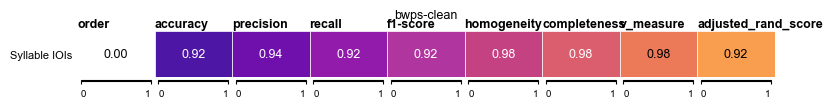

In [5]:
for dataset_id in ['bvs', 'ns', 'bwps', 'bwps-clean']:
    data = bird_scores.loc[dataset_id, :, :].drop(columns=['support']).set_index('label')
    fig, ax, cbar_axes = per_column_heatmap(
        data,
        cmap=cmap_slice('plasma', 0, 0.75),
        vmin=0, vmax=1,
        cbar_location='bottom',
        cbar_height=.03,
        cbar_xpad=.05,
        column_title=True,
        figsize=(len(data.columns) * 1, len(data) * 0.6),
    )
    plt.title(dataset_id, y=1.1)
    plt.tight_layout()
    plt.show()

## Label identity

In [6]:
from src.pipeline.fit_hmms import get_output_dir
from src.hmm.utils import load_fit, evaluate


### Main stats

In [7]:
# Load all fitted hmms and evaluate the labels against the annotated labels
label_scores = []
for dataset_id, rhythm_type in dataset_rhythm_types:
    if dataset_id.startswith('bwps') or dataset_id == 'rt':
        continue
    
    units = load_units(dataset_id, rhythm_type)
    units = units[~units['bird_id'].str.endswith('-tutee')]

    for bird_id in units['bird_id'].unique():
        bird_units = units.query(f'bird_id == "{bird_id}"')
        labels_true = bird_units['label']

        path = get_output_dir(dataset_id, rhythm_type) / f"{bird_id}.joblib"
        if not path.exists():
            print(bird_id, 'missing')
            continue

        result = load_fit(path)
        # The fit lists the chunks in chunk order, so the units must be too.
        assert bird_units['chunk_idx'].is_monotonic_increasing
        scores = evaluate(labels_true, np.concatenate(result["labels"]))
        del scores['confusion_matrix']
        del scores['confusion_matrix_labels']
        del scores['label_mapping']
        label_scores.append(dict(
            dataset_id=dataset_id,
            rhythm_type=rhythm_type,
            **scores,
        ))

label_scores = pd.DataFrame(label_scores).set_index(['dataset_id', 'rhythm_type'])

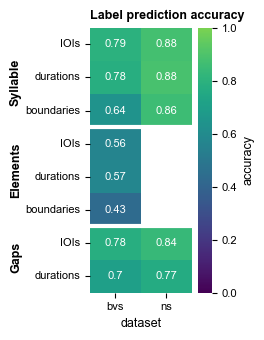

In [8]:
# Plot
label_accuracies = pd.concat([
    (label_scores
        .reset_index()
        .groupby(['dataset_id', 'rhythm_type'])['accuracy']
        .mean()
        .unstack('dataset_id')
        .reindex(index=DATASETS['bvs']['rhythm_types'])
    ),
    rhythm_types['unit_type_label']
], axis=1).set_index('unit_type_label')

plt.figure(figsize=(2.5, 3.5))
sns.heatmap(
    label_accuracies, 
    annot=True, 
    cmap=cmap_slice('viridis', 0, 0.8), 
    vmin=0, 
    vmax=1,
    annot_kws=dict(fontsize=8),
    cbar_kws=dict(label='accuracy')
)

ylabel_annot('Syllable', y=.75)
ylabel_annot('Elements', y=.5)
ylabel_annot('Gaps', y=.25)
plt.axhline(6, c='w', lw=3)
plt.axhline(3, c='w', lw=3)

plt.title('Label prediction accuracy', x=0, ha='left', fontweight='bold')
plt.xlabel('dataset')
plt.ylabel(None)
plt.tight_layout()


### Additional stats

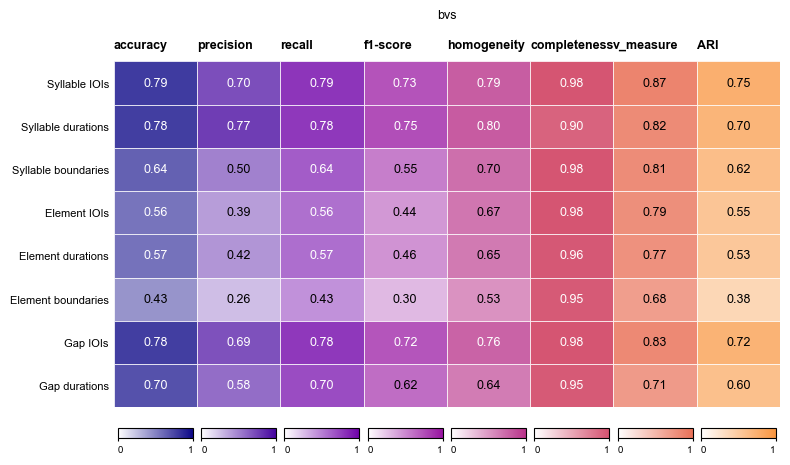

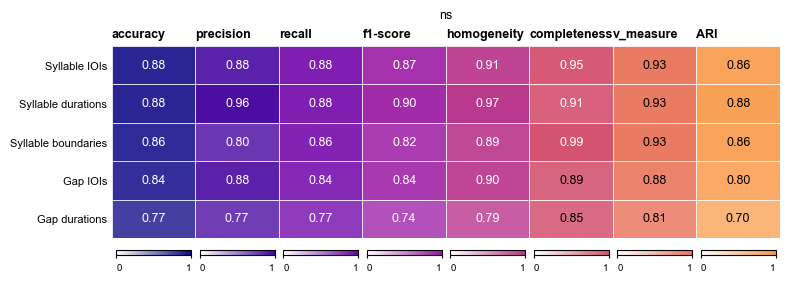

In [9]:
from src.viz.heatmap import per_column_heatmap, cmap_slice

# Average evaluation metrics per condition
summary = (
    label_scores
        .drop(columns=['aligned_pred'])
        .groupby(['dataset_id', 'rhythm_type'])
        .mean()
        .rename(columns={'adjusted_rand_score': 'ARI'})
        .round(2)
        .reindex(list(RHYTHM_TYPES), level='rhythm_type')
)
summary['label'] = summary.index.get_level_values('rhythm_type').map(lambda r: RHYTHM_TYPES[r]['label'])

for dataset_id in ['bvs', 'ns']:
    data = summary.loc[dataset_id].drop(columns=['support']).set_index('label')
    fig, ax, cbar_axes = per_column_heatmap(
        data,
        cmap=cmap_slice('plasma', 0, 0.75),
        vmin=0, vmax=1,
        cbar_location='bottom',
        cbar_height=.03,
        cbar_xpad=.05,
        column_title=True,
        figsize=(len(data.columns) * 1, len(data) * 0.6),
    )
    plt.title(dataset_id, y=1.1)
    plt.tight_layout()
    plt.show()

## Combined stats

In [10]:
combined_acc = pd.concat([
    bird_accuracies.rename(
        columns={col: ('bird', col) for col in bird_accuracies.columns}
    ),
    label_accuracies.rename(
        columns={col: ('label', col) for col in bird_accuracies.columns}
    ),
], axis=1)
combined_acc.columns = pd.MultiIndex.from_tuples(combined_acc.columns)

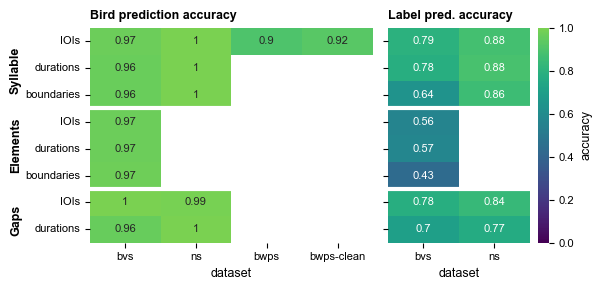

In [11]:
fig, (ax0, ax1) = plt.subplots(1, 2, sharey=True, figsize=(6, 3), width_ratios=[4, 2.5])

ax0.set_title('Bird prediction accuracy', x=0, ha='left', fontweight='bold')
sns.heatmap(
    combined_acc['bird'], 
    annot=True, 
    cmap=cmap_slice('viridis', 0, 0.8), 
    vmin=0, 
    vmax=1,
    annot_kws=dict(fontsize=8),
    # cbar_kws=dict(label='accuracy')
    ax=ax0,
    cbar=False
)

ax1.set_title('Label pred. accuracy', x=0, ha='left', fontweight='bold')
sns.heatmap(
    combined_acc['label'], 
    annot=True, 
    cmap=cmap_slice('viridis', 0, 0.8), 
    vmin=0, 
    vmax=1,
    annot_kws=dict(fontsize=8),
    cbar_kws=dict(label='accuracy'),
    ax=ax1
)

plt.sca(ax0)
ax0.set_ylabel(None)
ax1.set_ylabel(None)
ylabel_annot('Syllable', y=.75)
ylabel_annot('Elements', y=.5)
ylabel_annot('Gaps', y=.25)
ax0.axhline(6, c='w', lw=3)
ax1.axhline(6, c='w', lw=3)
ax0.axhline(3, c='w', lw=3)
ax1.axhline(3, c='w', lw=3)

# plt.title('Bird identity prediction accuracy', x=0, ha='left', fontweight='bold')
ax0.set_xlabel('dataset')
ax1.set_xlabel('dataset')
plt.tight_layout()

savefig('figS3-prediction-accuracy')